# Miniprojekt B

## Frekvensanalyse af EKG, EMG og Blodtryk

**Navne:** Jakob og Lucas 

**AU-ID:**  AU728859 og AU673726


### Indhold:
1. sampletid og tidsplot af muskelsignalerne
2. Frekvenstransformation af 630 signaler
3. Energi under og over 200 Hz
4. Zero-padding til ottedobbeltlængde 
5. R-takker, puls og Heart Rate Variability
6. STFT og frekvensindhold i hvert QRS-kompleks
7. Tre blodtrykssignaler med og uden spektral udglatning
8. Bogopgaver og samlet konklusion


ja troede i starten at vi skulle lave en funktion som hed analysatoren som har blot lige gemt den her men nåede ikke i mål synes det lød dumt 

In [1]:
def frekvensanalyse(x, fsample, N=None):
    """
    Beregner et ensidet amplitude- og energispektrum.

    x       : målt signal
    fsample : samplefrekvens i Hz
    N       : FFT-længde. N >= len(x)
    """
    x = np.asarray(x, dtype=float).ravel()
    L = len(x)
    
    # DFT beregnet med FFT-algoritmen
    X = np.fft.rfft(x, n=N)
    f = np.fft.rfftfreq(N, d=1 / fsample)

    # Ensidet amplitudespektrum
    amplitude = np.abs(X) / L

    # Energi pr. frekvens-bin ifølge Parsevals sætning
    Ebin = np.abs(X)**2 / N

    if N % 2 == 0:
        # Fordobl alle punkter undtagen DC og Nyquist
        amplitude[1:-1] *= 2
        Ebin[1:-1] *= 2
    else:
        # Ved ulige N findes intet Nyquist-punkt
        amplitude[1:] *= 2
        Ebin[1:] *= 2

    return {
        "f": f,
        "X": X,
        "amplitude": amplitude,
        "Ebin": Ebin,
        "E_time": np.sum(x**2),
        "E_frequency": np.sum(Ebin),
        "df": fsample / N,
        "L": L,
        "N": N
    }

## 1. sampletid og tidsplot af muskelsignalerne

"Importer de to muskelsignaler fra Brightspace ‘EMG_Healthy’ og
‘EMG_Myopathy’. Bestem sampletiden og dernæst samplefrekvensen - og plot
så de første 630 samples af begge signaler. Beskriv ligheder og forskelle"

EMG-målepunkter pr signal: Healthy: 630 Myopathy: 630
Healthy:  Sampletiden (Ts) = 0.000250 s
Myopathy: Sampletiden (Ts) = 0.000250 s
Healthy: Samplefrekvens (fs) = 4000 Hz
Myopathy: Samplefrekvens (fs) = 4000 Hz


Text(0, 0.5, 'Amplitude')

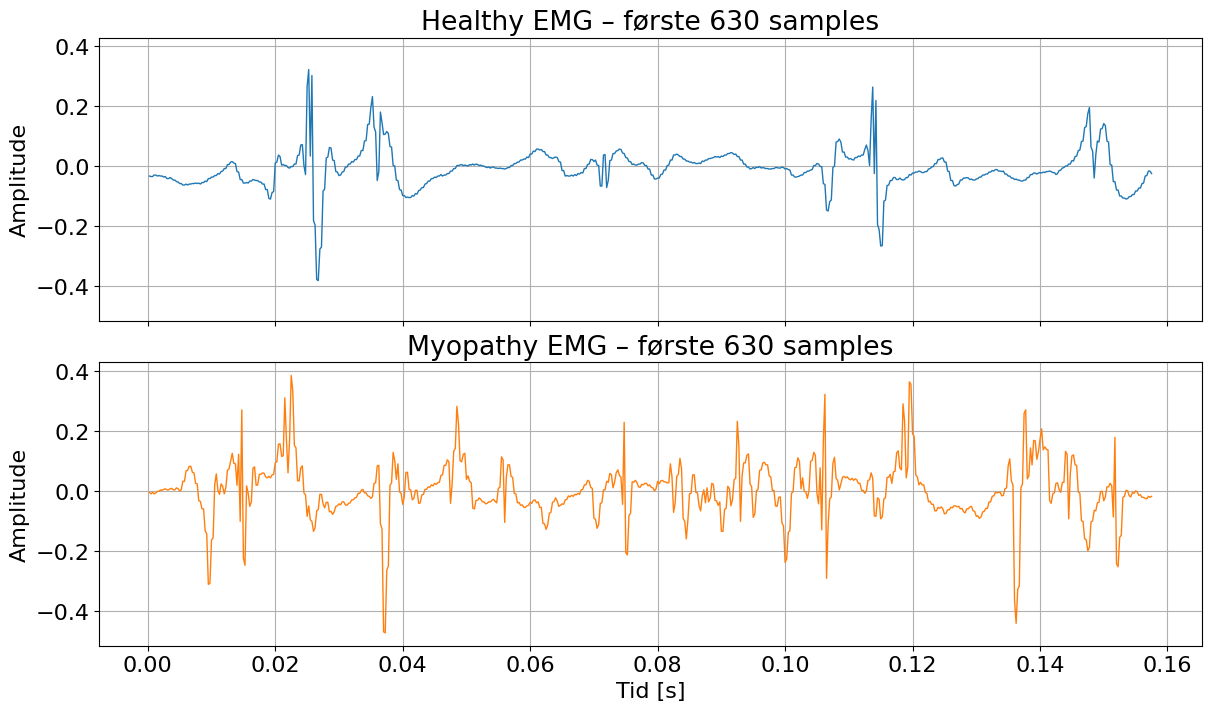

In [2]:
import numpy as np
from scipy import signal
from scipy.io import loadmat
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["font.size"] = 16
plt.rcParams["axes.grid"] = True

healthy = np.loadtxt("EMG_Healthy.txt", max_rows=630)
myopathy = np.loadtxt("EMG_Myopathy.txt", max_rows=630)

# Kolonne 0 = tid, kolonne 1 = EMG signal
t_healthy = healthy[:, 0]
x_healthy = healthy[:, 1]

t_myopathy = myopathy[:, 0]
x_myopathy = myopathy[:, 1]

#målinger pr sekund
dt_healthy = t_healthy[1] - t_healthy[0]
dt_myopathy = t_myopathy[1] - t_myopathy[0]

# Sample frekvens
fs_healthy = 1 / dt_healthy
fs_myopathy = 1 / dt_myopathy

print("EMG-målepunkter pr signal:", "Healthy:", len(x_healthy), "Myopathy:", len(x_myopathy))
print(f"Healthy:  Sampletiden (Ts) = {dt_healthy:.6f} s")
print(f"Myopathy: Sampletiden (Ts) = {dt_myopathy:.6f} s")
print(f"Healthy: Samplefrekvens (fs) = {fs_healthy:.0f} Hz")
print(f"Myopathy: Samplefrekvens (fs) = {fs_myopathy:.0f} Hz")

emg = {"healthy": {
    "t": t_healthy,
    "x": x_healthy,
    "dt": dt_healthy,
    "fs": fs_healthy
}
, "myopathy": {
    "t": t_myopathy,
    "x": x_myopathy,
    "dt": dt_myopathy,
    "fs": fs_myopathy
}
}

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True)

ax[0].plot(t_healthy, x_healthy, linewidth=1)
ax[0].set_title("Healthy EMG – første 630 samples")
ax[0].set_ylabel("Amplitude")

ax[1].plot(t_myopathy, x_myopathy, linewidth=1, color="tab:orange")
ax[1].set_title("Myopathy EMG – første 630 samples")
ax[1].set_xlabel("Tid [s]")
ax[1].set_ylabel("Amplitude")

Sampletiden findes som forskellen mellem to på hinanden følgende
tidspunkter:

Sampletiden beregnes som:

$$
T_s = t_1 - t_0 = 0{,}00025\,\mathrm{s}
$$

Samplefrekvensen bliver derfor:

$$
f_s = \frac{1}{T_s}
= \frac{1}{0{,}00025\,\mathrm{s}}
= 4000\,\mathrm{Hz}
$$

Begge EMG-signaler har dermed samme sampletid og samplefrekvens.
Begge signaler svinger omkring nul og indeholder både positive og
negative, ikke-periodiske udsving.

I de første 630 samples fremstår signalet fra personen med myopati
mere uroligt og indeholder flere hyppige og skarpe udsving. Det raske
signal har generelt længere rolige områder, som afbrydes af enkelte
tydelige aktivitetsudbrud.

## 2. Frekvenstransformation af 630 signaler

"Lav frekvenstransformation på de første 630 samples af signalerne i 1), benyt
N=2000 og vis frekvensspektrene. Beskriv igen ligheder og forskelle"

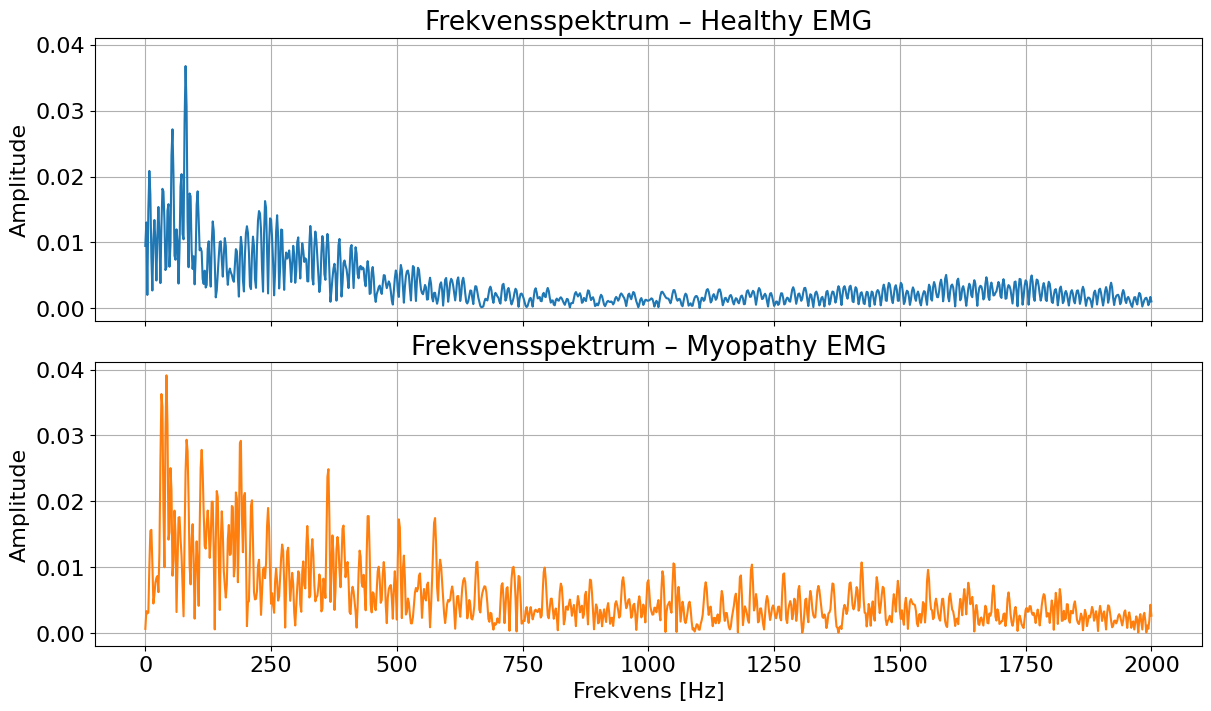

In [3]:
# FFT-længde
N = 2000
L = 630

def frekvensspektrum(x, fs, N):
    x = np.asarray(x)
    L = len(x)

    # FFT med zero-padding fra 630 til 2000 punkter
    X = np.fft.rfft(x, n=N)

    # Frekvensakse fra 0 til Nyquistfrekvensen
    f = np.fft.rfftfreq(N, d=1/fs)

    # Ensidet amplitudespektrum
    A = np.abs(X) / L
    A[1:-1] *= 2

    return f, A

f_healthy, A_healthy = frekvensspektrum(emg["healthy"]["x"], emg["healthy"]["fs"], N)
f_myopathy, A_myopathy = frekvensspektrum(emg["myopathy"]["x"], emg["myopathy"]["fs"], N)

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

ax[0].plot(f_healthy, A_healthy)
ax[0].set_title("Frekvensspektrum – Healthy EMG")
ax[0].set_ylabel("Amplitude")

ax[1].plot(f_myopathy, A_myopathy, color="tab:orange")
ax[1].set_title("Frekvensspektrum – Myopathy EMG")
ax[1].set_xlabel("Frekvens [Hz]")
ax[1].set_ylabel("Amplitude")

plt.show()

FFT-længde på \(N=2000\). Signalerne er blevet
zero-paddet med 1370 nuller. Frekvensopløsningen i det viste spektrum er:

$$
\Delta f = \frac{f_s}{N}
= \frac{4000}{2000}
= 2\,\mathrm{Hz}
$$

begge signaler har hovedsageligt deres største amplituder ved de lavere frekvenser. 

Den største spektrale amplitude findes omkring 80-100 Hz for det raske signal og omkring 40-50 Hz for myopati-signalet. Myopati-signalet har flere fremtrædende toppe fordelt over frekvensaksen, hvilket viser, at dets variationer er fordelt over et bredere frekvensområde. Dette hænger sammen med de hyppigere og skarpere udsving, som ses ovenover i tidsdomænet.

### 3. Energi under og over 200 Hz

"Bestem lavfrekvent energi (under 200Hz) og højfrekvent energi (over 200Hz) for
de to signaler og sammenlign det sunde muskelsignal med det for muskelsvind"

Brug samme segment på 630 samples og samme FFT-længde N=2000. Energien beregnes med Parsevals sætning:
$$
E=\sum_n |x[n]|^2
=\frac{1}{N}\sum_k |X[k]|^2
$$
Her placeres frekvenspunktet præcis ved 200 Hz i det lavfrekvente område:

In [4]:
def beregn_energiområder(x, fs, N=2000, grænse=200):
    x = np.asarray(x)
    
    # DFT med zero-padding
    X = np.fft.rfft(x, n=N)
    f = np.fft.rfftfreq(N, d=1/fs)

    # Energi pr. frekvens-bin
    Ebin = np.abs(X)**2 / N

    # Fordobling ved ensidet spektrum,
    # undtagen DC og Nyquist
    if N % 2 == 0:
        Ebin[1:-1] *= 2
    else:
        Ebin[1:] *= 2

    # 200 Hz medtages i det lavfrekvente område
    E_lav = np.sum(Ebin[f <= grænse])
    E_høj = np.sum(Ebin[f > grænse])
    E_total = E_lav + E_høj

    return {
        "lav": E_lav,
        "høj": E_høj,
        "total": E_total,
        "lav_procent": 100 * E_lav / E_total,
        "høj_procent": 100 * E_høj / E_total
    }


energi_healthy = beregn_energiområder(
    x_healthy, fs_healthy
)

energi_myopathy = beregn_energiområder(
    x_myopathy, fs_myopathy
)

for navn, energi in [
    ("Healthy", energi_healthy),
    ("Myopathy", energi_myopathy)
]:
    print(navn)
    print(f"  Lavfrekvent energi: {energi['lav']:.4f}")
    print(f"  Højfrekvent energi: {energi['høj']:.4f}")
    print(f"  Lavfrekvent andel:  {energi['lav_procent']:.2f} %")
    print(f"  Højfrekvent andel:  {energi['høj_procent']:.2f} %")
    print(f"  Total energi:       {energi['total']:.4f}")

Healthy
  Lavfrekvent energi: 1.4414
  Højfrekvent energi: 1.2251
  Lavfrekvent andel:  54.06 %
  Højfrekvent andel:  45.94 %
  Total energi:       2.6666
Myopathy
  Lavfrekvent energi: 2.8801
  Højfrekvent energi: 2.9435
  Lavfrekvent andel:  49.46 %
  Højfrekvent andel:  50.54 %
  Total energi:       5.8236


Myopati-signalet har mere absolut energi i begge
frekvensområder. Den lavfrekvente energi er cirka dobbelt så stor,
mens den højfrekvente energi er cirka 2.5 gange så stor som for
det raske signal. Det raske signal har størstedelen af sin energi
under 200 Hz, mens myopati-signalets energi er næsten ligeligt
fordelt, med en lidt større andel over 200 Hz.

### 4. Zero-padding til ottedobbeltlængde 

"Zero-pad ‘EMG_Healthy’ til ottedobbelt længde. Lav igen frekvenstransformation
(nu med N=16000) og sammenlign med det tilsvarende spektrum fra 2"

N = 2000:  Δf = 2.00 Hz
N = 16000: Δf = 0.25 Hz


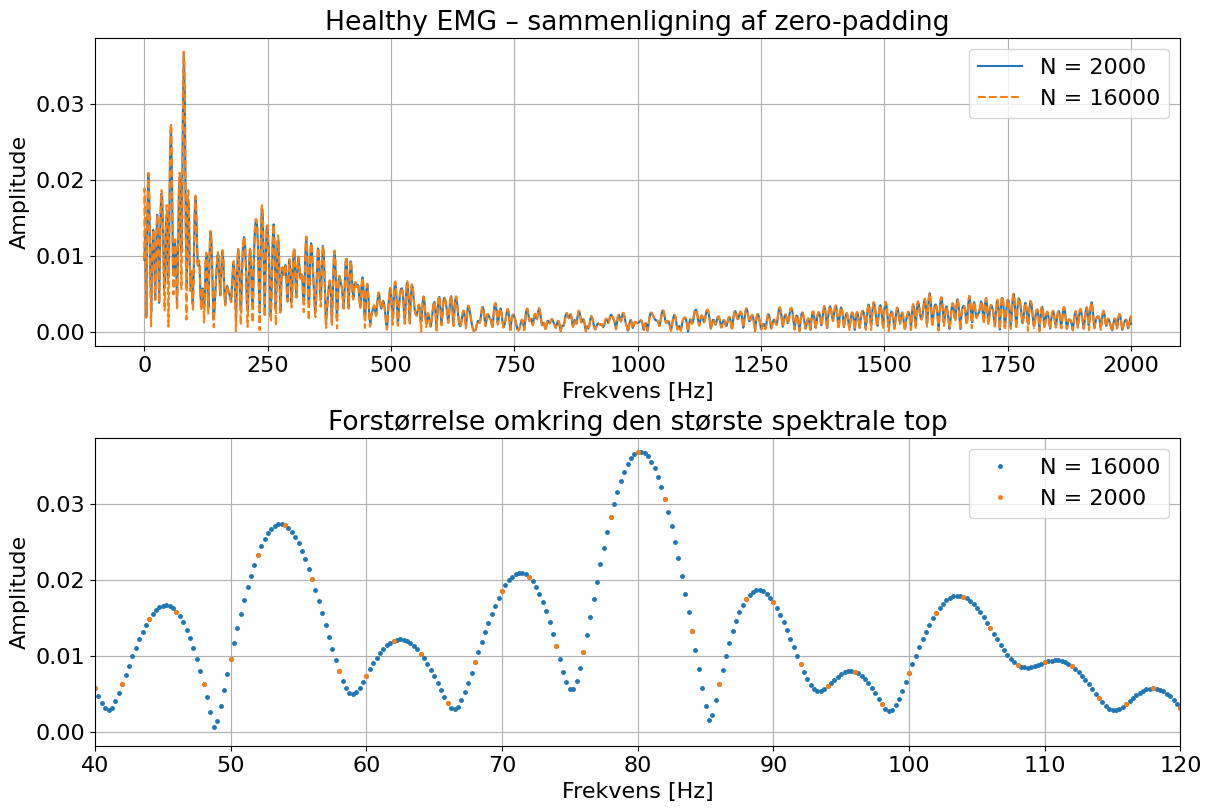

In [5]:

x = x_healthy

# Spektrum fra opgave 2
f_2000, A_2000 = frekvensspektrum(
    x, fs_healthy, N=2000
)

# Otte gange større FFT-længde
f_16000, A_16000 = frekvensspektrum(
    x, fs_healthy, N=16000
)

print(f"N = 2000:  Δf = {fs_healthy / 2000:.2f} Hz")
print(f"N = 16000: Δf = {fs_healthy / 16000:.2f} Hz")

fig, ax = plt.subplots(
    2, 1,
    figsize=(12, 8),
    constrained_layout=True
)

# Hele frekvensområdet
ax[0].plot(f_2000, A_2000, label="N = 2000")
ax[0].plot(f_16000, A_16000, linestyle="--", label="N = 16000")
ax[0].set_title("Healthy EMG – sammenligning af zero-padding")
ax[0].set_xlabel("Frekvens [Hz]")
ax[0].set_ylabel("Amplitude")
ax[0].legend()

# Forstørret område omkring den største top
ax[1].plot(f_16000, A_16000,".", markersize=5, label="N = 16000")
ax[1].plot(f_2000, A_2000, ".", markersize=5, label="N = 2000")
ax[1].set_xlim(40, 120)
ax[1].set_title("Forstørrelse omkring den største spektrale top")
ax[1].set_xlabel("Frekvens [Hz]")
ax[1].set_ylabel("Amplitude")
ax[1].legend()

plt.show()

Ved frekvenstransformationen med \(N=16000\) tilføjes der derfor
15370 nuller efter signalet.

Frekvensopløsningen ved \(N=2000\) var:

$$
\Delta f_{2000}
= \frac{4000}{2000}
= 2\,\mathrm{Hz}
$$

Ved \(N=16000\) bliver frekvensopløsningen:

$$
\Delta f_{16000}
= \frac{4000}{16000}
= 0{,}25\,\mathrm{Hz}
$$

De to spektre har samme overordnede form og omtrent samme
amplituder, fordi de er beregnet ud fra de samme målte samples.
Spektret med \(N=16000\) fremstår dog mere glat og detaljeret,

Zero-padding tilfører ikke ny information til signalet og forbedrer
ikke den egentlige evne til at adskille tætliggende frekvenser.
Det giver alene en tættere sampling af det eksisterende spektrum,
så det bliver lettere at aflæse og estimere placeringen af toppene.*

### 5. R-takker, puls og Heart Rate Variability

"Pulsen i et EKG-signal kan findes som gennemsnitsafstanden mellem kompleksernes R-takke. Vis hvordan, og diskuter hvor på frekvensspektret den samme
information må kunne findes. Man bør inddrage begrebet Heart Rate Variability."

Ved denne opgave kommer det til udtryk at vi begge er Datavidenskabs studerende og derfor ikke ved så meget indenfor sundhedsteknologi. Vi har brugt https://en.wikipedia.org/wiki/Heart_rate_variability og AI til at forstå 

R-takkerne findes som lokale maksima over en tærskel, med et mindste mellemrum på ca. 0.4 s, så samme QRS ikke giver to detektioner.

`signal.find_peaks`-funktionen fra scipy bruges til at finde disse peaks

**distance:** er den mindste tilladte afstand mellem to toppe, målt i samples. Her kræver vi mindst 0,4 sekunder mellem R-takkerne:
distance = 0.4 * 2000 = 800 samples

**prominence:** beskriver, hvor meget en top skal skille sig ud fra sine omgivelser.
prominence = 3 * np.std(ecg)

24650 EKG-målepunkter
Antal fundne R-takker: 13
Gennemsnitlig RR-afstand: 0.9575 s
Gennemsnitlig puls: 62.66 slag/min


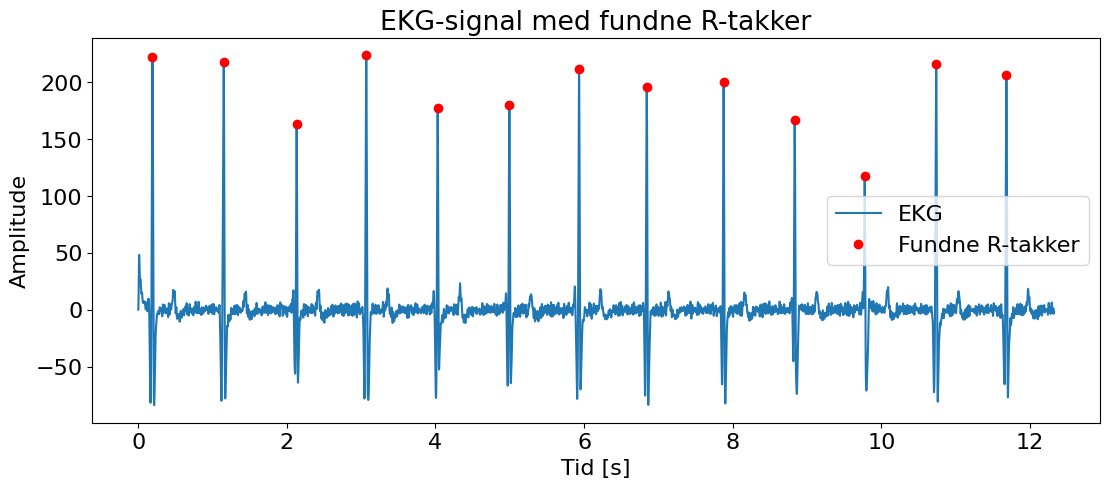

In [6]:
#Indlæs EKG-data
mat = loadmat("ECG_complex.mat")

#ravel() smaler EKG-målepunkterne i en endimensional array
ecg = mat["signal_EKG"].ravel()

#item() henter sample frekvensen et tal
fs_ecg = mat["f_sample"].item()

# Tidsakse til EKG-signalet
t_ecg = np.arange(len(ecg)) / fs_ecg

print(len(ecg), "EKG-målepunkter")

# Find R-takker
r_peaks, properties = signal.find_peaks(
    ecg,
    distance=int(0.4 * fs_ecg),
    prominence=3 * np.std(ecg)
)

r_times = r_peaks / fs_ecg

# Afstanden mellem R-takkerne
rr_intervals = np.diff(r_times)

# Gennemsnitlig RR-afstand og puls
mean_rr = np.mean(rr_intervals)
pulse_bpm = 60 / mean_rr

print(f"Antal fundne R-takker: {len(r_peaks)}")
print(f"Gennemsnitlig RR-afstand: {mean_rr:.4f} s")
print(f"Gennemsnitlig puls: {pulse_bpm:.2f} slag/min")

plt.figure(figsize=(13, 5))

plt.plot(t_ecg, ecg, label="EKG")
plt.plot(
    r_times,
    ecg[r_peaks],
    "ro",
    label="Fundne R-takker"
)

plt.xlabel("Tid [s]")
plt.ylabel("Amplitude")
plt.title("EKG-signal med fundne R-takker")
plt.legend()
plt.grid()
plt.show()

på plottet ovenfor er R-takkerne markeret med røde prikker.

Den gennemsnitlige RR-afstand blev bestemt til $0{,}9575\,\mathrm{s}$, hvilket giver en gennemsnitlig puls på:

$$
\mathrm{puls}
=
\frac{60}{0{,}9575}
\approx 62{,}66\ \mathrm{slag/min}
$$


Nedenfor plottes et histogram over RR-afstandende

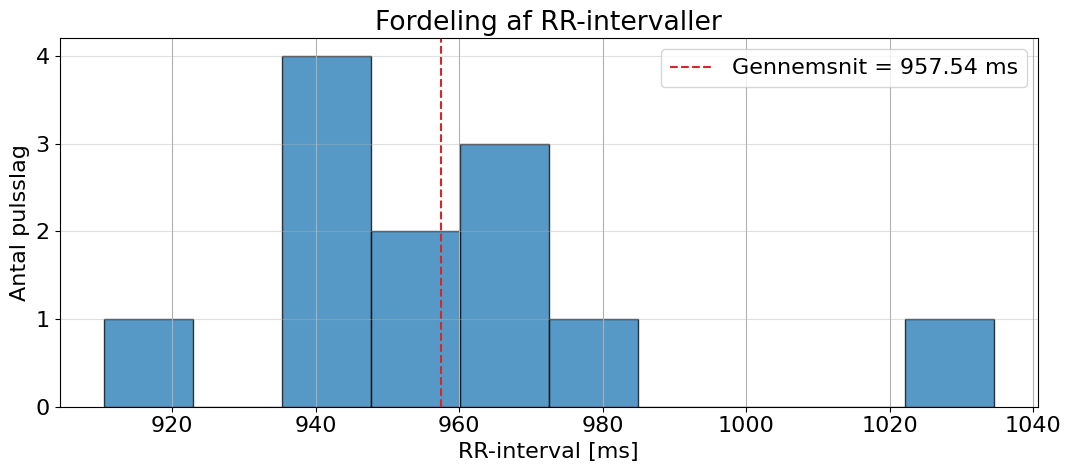

Standardafvigelse: 30.11 ms


In [21]:
# RR-intervaller fra sekunder til millisekunder
rr_ms = rr_intervals * 1000

# Beregn middelværdi og standardafvigelse
mean_rr = np.mean(rr_intervals) * 1000
std = np.std(rr_ms, ddof=1)

plt.figure(figsize=(11, 5))

plt.hist(
    rr_ms,
    bins=10,
    color="tab:blue",
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    mean_rr,
    color="tab:red",
    linestyle="--",
    label=f"Gennemsnit = {mean_rr:.2f} ms"
)

plt.xlabel("RR-interval [ms]")
plt.ylabel("Antal pulsslag")
plt.title("Fordeling af RR-intervaller")
plt.grid(axis="y", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Standardafvigelse: {std:.2f} ms")

std beskriver den samlede variation i RR-intervallernes længde.


Nedenfor bruger vi `ax.set_xlim(0, 5)`til at se nærmere på de først 0-5 Hz af frekvensspektret over EKG-signalet. Vi forventer at se toppe omkring frekvensen:

$$
f_{\mathrm{puls}}
=
\frac{1}{0{,}9575}
\approx 1{,}044\,\mathrm{Hz}
$$

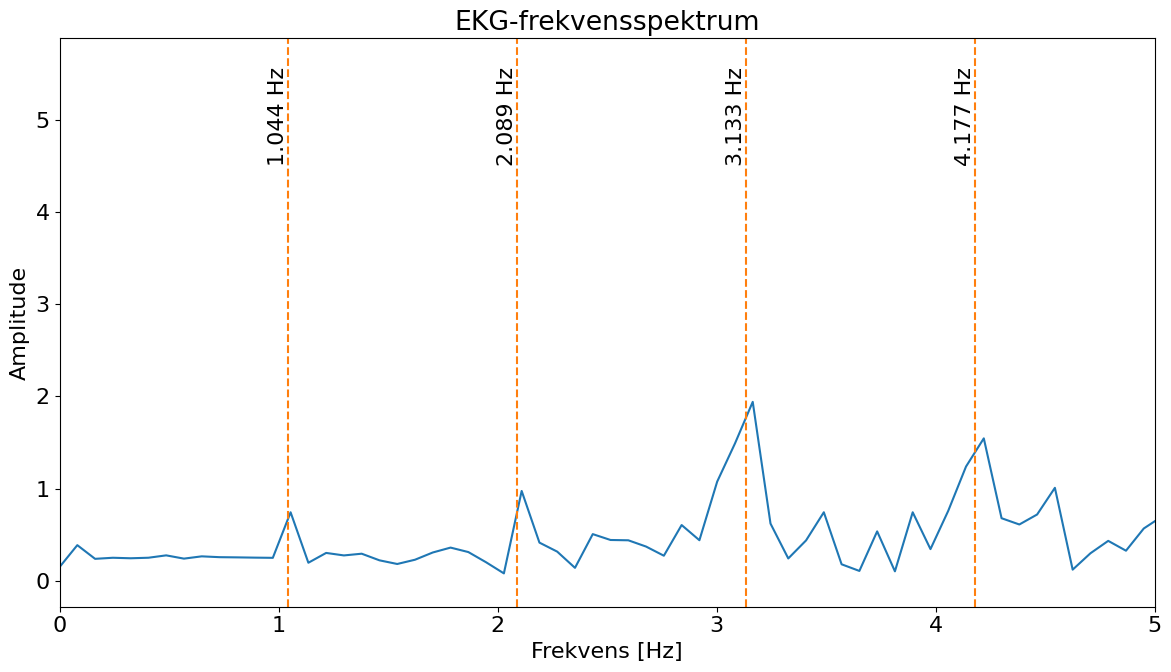

In [18]:
f_ecg, A_ecg = frekvensspektrum(
    ecg, fs_ecg, N=len(ecg)
)

pulse_hz = 1 / np.mean(rr_intervals)

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(f_ecg, A_ecg)
ax.set_title("EKG-frekvensspektrum")
ax.set_ylabel("Amplitude")
ax.set_xlabel("Frekvens [Hz]")

for i in range(1, 5):
    frequency = i * pulse_hz

    ax.axvline(
        frequency,
        linestyle="--",
        color="tab:orange"
    )

    ax.text(
        frequency,
        0.95,
        f"{frequency:.3f} Hz",
        transform=ax.get_xaxis_transform(),
        rotation=90,
        va="top",
        ha="right"
    )

ax.set_xlim(0, 5)
ax.grid()
plt.tight_layout()
plt.show()

På EKG-spektret findes en frekvenskomponent omkring
$1{,}04\,\mathrm{Hz}$. Det er den samme pulsinformation, som blev
fundet ud fra R-takkerne. 

Der ses også frekvenskomponenter ved multipla af pulsfrekvensen.
Disse opstår, fordi QRS-komplekset har en skarp og
ikke-sinusformet form. Grundfrekvensen ved cirka $1{,}04\,\mathrm{Hz}$
behøver derfor ikke at være spektrets største top.

RR-intervallerne er ikke helt ens, hvilket betegnes Heart Rate
Variability. Denne variation gør, at frekvensindholdet omkring
pulsfrekvensen og dens harmoniske bliver mere spredt.

### 6. STFT og frekvensindhold i hvert QRS-kompleks


"Lav STFT på EKG-signalet og vis frekvensindholdet for hvert QRS-kompleks."

EKG-signalet blev analyseret med en Short-Time Fourier Transform.
Der blev anvendt et Hann-vindue med en længde på 200 ms (400 samples) og 90 %
overlap. Et kort vindue er valgt, fordi QRS-komplekserne er
kortvarige, og det skal være muligt at adskille dem i tid.

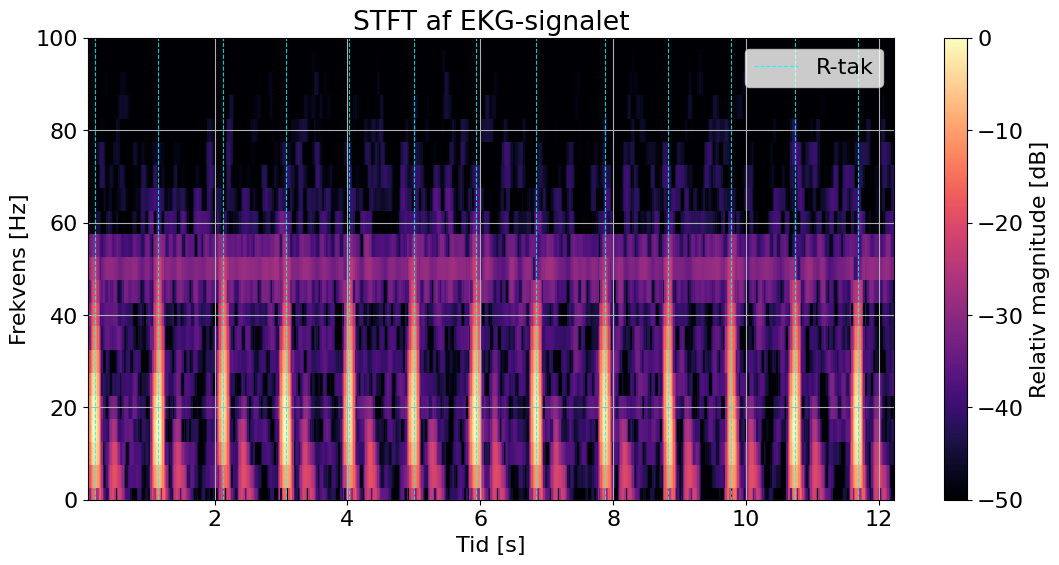

In [9]:
# Fjern signalets middelværdi
ecg_centered = ecg - np.mean(ecg)

# STFT-parametre
window_length = int(0.2 * fs_ecg)     # 200 ms
overlap = int(0.9 * window_length)    # 90 % overlap
N_fft = window_length # 2048 # 24650 # Zero padding?

f_stft, t_stft, Z_stft = signal.stft(
    ecg_centered,
    fs=fs_ecg,
    window="hann",
    nperseg=window_length,
    noverlap=overlap,
    nfft=N_fft,
    boundary=None,
    padded=False
)

# Relativ magnitude i dB
magnitude = np.abs(Z_stft)

magnitude_db = 20 * np.log10(
    magnitude / np.max(magnitude) + 1e-12
)

# Vis kun det relevante frekvensområde
frequency_mask = f_stft <= 100

fig, ax = plt.subplots(figsize=(13, 6))

image = ax.pcolormesh(
    t_stft,
    f_stft[frequency_mask],
    magnitude_db[frequency_mask],
    shading="auto",
    cmap="magma",
    vmin=-50,
    vmax=0
)

# Markér tidspunktet for hver R-tak
for i, r_time in enumerate(r_times):
    ax.axvline(
        r_time,
        color="cyan",
        linestyle="--",
        linewidth=0.8,
        alpha=0.8,
        label="R-tak" if i == 0 else None
    )

ax.set_xlabel("Tid [s]")
ax.set_ylabel("Frekvens [Hz]")
ax.set_title("STFT af EKG-signalet")
ax.set_ylim(0, 100)
ax.legend()

fig.colorbar(
    image,
    ax=ax,
    label="Relativ magnitude [dB]"
)

plt.show()

I spektrogrammet ses hvert QRS-kompleks som et lyst, næsten lodret
område omkring tidspunktet for den tilhørende R-tak. De lodrette
områder opstår, fordi QRS-komplekset indeholder hurtige og skarpe
ændringer og derfor har frekvensindhold over et bredt
frekvensområde. Mellem QRS-komplekserne er den spektrale amplitude
generelt mindre.

Der ses desuden en komponent omkring 50 Hz, som er til stede over
næsten hele optagelsen. Måske støj?

STFT'en viser dermed både tidspunktet og frekvensindholdet for
hvert QRS-kompleks. Dette kan ikke ses i én almindelig Fourier-
transformation, fordi den kun viser signalets samlede
frekvensindhold og ikke, hvornår de enkelte frekvenskomponenter
optræder.

Vi trækker alle de 13 QRS-komplekser ud og kigger her mere specifikt på amplitude forskellene

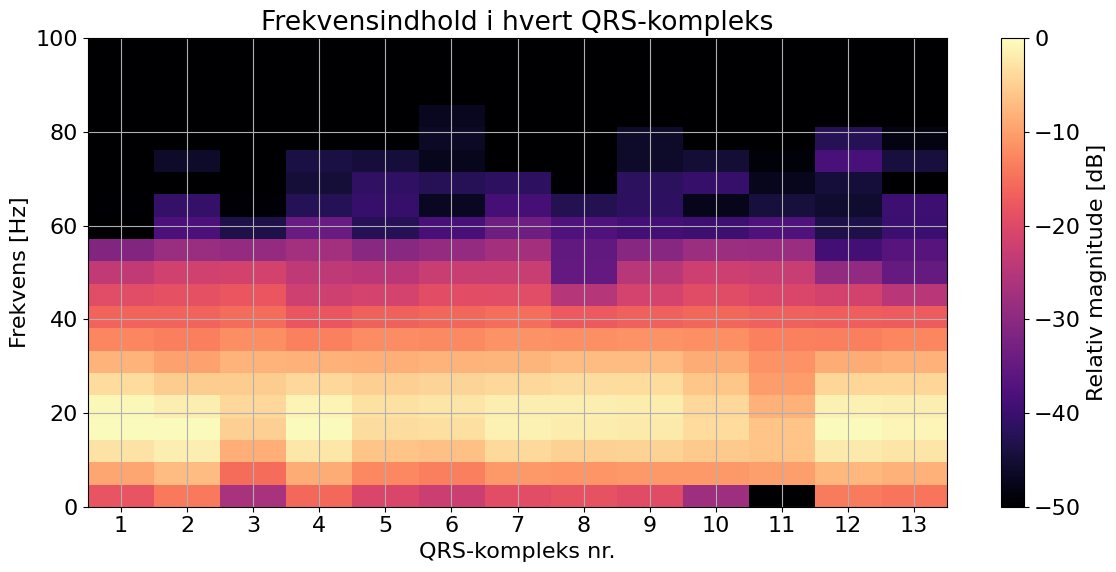

In [10]:
# Find STFT-vinduet nærmest hver R-tak
qrs_columns = np.array([
    np.argmin(np.abs(t_stft - r_time))
    for r_time in r_times
])

# Frekvensindhold ved hvert QRS-kompleks
qrs_spectra_db = magnitude_db[
    frequency_mask
][:, qrs_columns]

plt.figure(figsize=(12, 6))

plt.imshow(
    qrs_spectra_db,
    aspect="auto",
    origin="lower",
    extent=[
        0.5,
        len(r_peaks) + 0.5,
        f_stft[frequency_mask][0],
        f_stft[frequency_mask][-1]
    ],
    cmap="magma",
    vmin=-50,
    vmax=0
)

plt.xlabel("QRS-kompleks nr.")
plt.ylabel("Frekvens [Hz]")
plt.title("Frekvensindhold i hvert QRS-kompleks")

plt.xticks(
    np.arange(1, len(r_peaks) + 1)
)

plt.colorbar(
    label="Relativ magnitude [dB]"
)

plt.tight_layout()
plt.show()

QRS-komplekserne har overordnet et lignende frekvensindhold, fordi
deres former minder om hinanden. Forskelle i farveintensiteten
skyldes blandt andet variationer i QRS-kompleksernes amplitude og
form.

### 7. Tre blodtrykssignaler med og uden spektral udglatning

"Find selv tre forskellige blodtryks-signaler (kig eventuelt på hjemmesiden
www.physionet.org). Lav frekvenstransformation og vis spektrene – både med
og uden udglatning. Diskuter forskellene"

In [11]:
from scipy.ndimage import uniform_filter1d

data = np.load("Blodtryk_signaler.npz")

fs_blood = float(data["fsample"])

blood_signals = {
    "slp01a": data["slp01a"],
    "slp02a": data["slp02a"],
    "slp03": data["slp03"]
}

print(f"Samplefrekvens: {fs_blood:.0f} Hz")

for name, x in blood_signals.items():
    print(
        f"{name}: {len(x)} samples, "
        f"{len(x) / fs_blood:.1f} sekunder"
    )

Samplefrekvens: 250 Hz
slp01a: 15000 samples, 60.0 sekunder
slp02a: 15000 samples, 60.0 sekunder
slp03: 15000 samples, 60.0 sekunder


In [12]:
def blodtryk_spektrum(
    x,
    fs,
    smoothing_bins=11
):
    x = np.asarray(x)
    L = len(x)

    # Fjern middelværdien, så DC-komponenten ikke dominerer
    x_centered = x - np.mean(x)

    # Hann-vindue reducerer spektrallækage
    window = np.hanning(L)

    # Frekvenstransformation
    X = np.fft.rfft(x_centered * window)
    f = np.fft.rfftfreq(L, d=1 / fs)

    # Ensidet amplitudespektrum
    amplitude = np.abs(X) / np.sum(window)

    if L % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2

    # Glidende middelværdi over frekvenspunkterne
    amplitude_smooth = uniform_filter1d(
        amplitude,
        size=smoothing_bins,
        mode="nearest"
    )

    return f, amplitude, amplitude_smooth

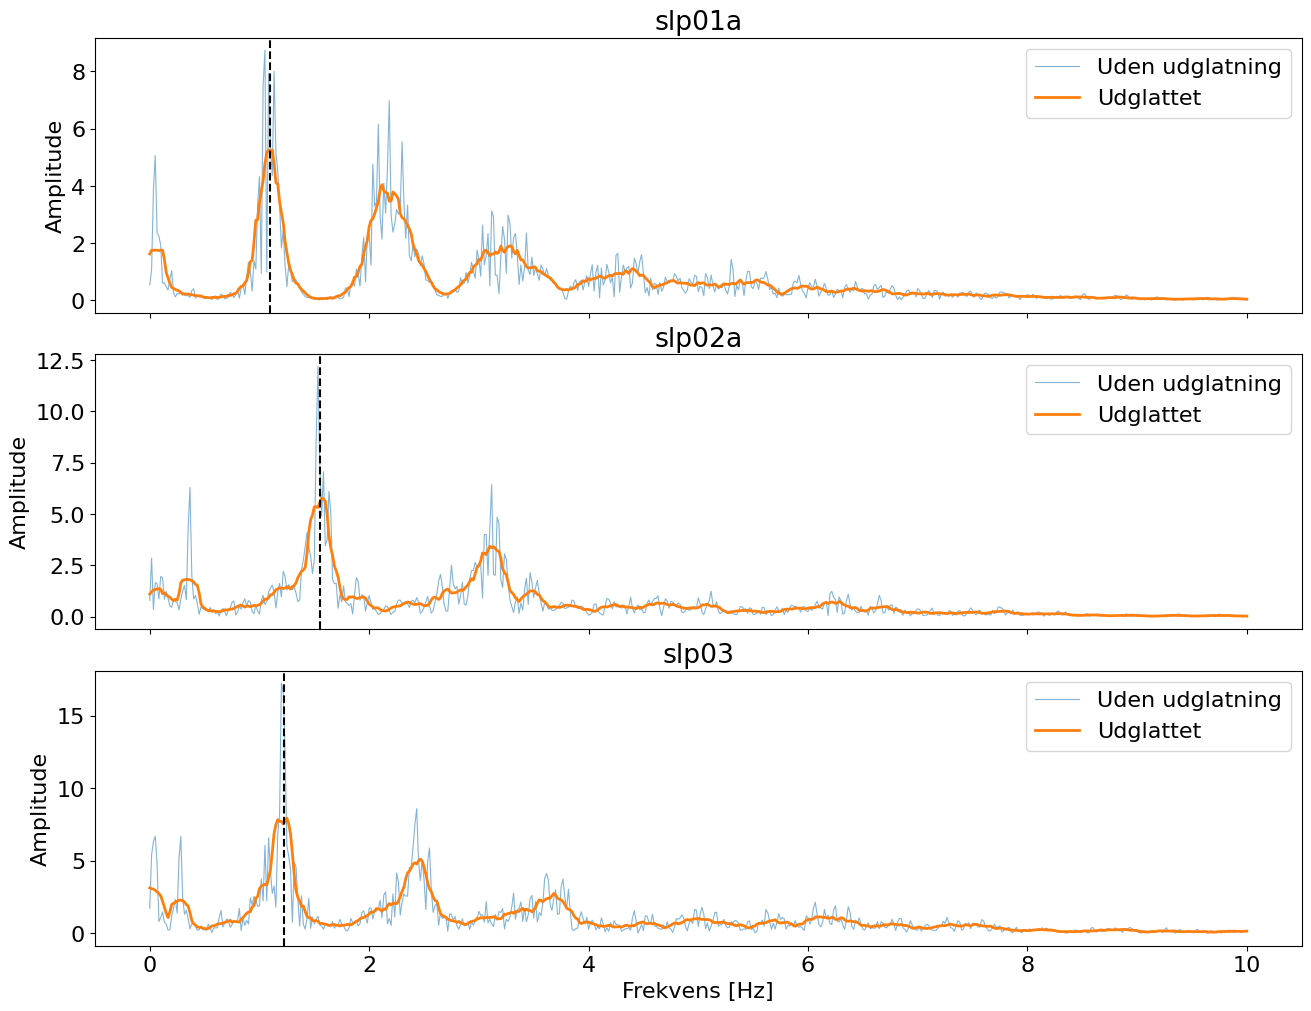

In [13]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(13, 10),
    sharex=True,
    constrained_layout=True
)

for ax, (name, x) in zip(
    axes,
    blood_signals.items()
):
    f, amplitude, amplitude_smooth = (
        blodtryk_spektrum(
            x,
            fs_blood,
            smoothing_bins=11
        )
    )

    # Blodtrykkets vigtigste information ligger
    # hovedsageligt ved lave frekvenser
    mask = f <= 10

    ax.plot(
        f[mask],
        amplitude[mask],
        linewidth=0.8,
        alpha=0.55,
        label="Uden udglatning"
    )

    ax.plot(
        f[mask],
        amplitude_smooth[mask],
        linewidth=2,
        color="tab:orange",
        label="Udglattet"
    )

    ax.set_title(name)
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid()

axes[-1].set_xlabel("Frekvens [Hz]")

axes[0].axvline(
    x=1.1,
    color="k",
    linestyle="--",
    label="1 Hz"
)
axes[1].axvline(
    x=1.55,
    color="k",
    linestyle="--",
    label="1 Hz"
)

axes[2].axvline(
    x=1.22,
    color="k",
    linestyle="--",
    label="1 Hz"
)

plt.show()

De tre blodtrykssignaler er samplet med $250\,\mathrm{Hz}$ og
indeholder hver 15000 samples, svarende til 60 sekunders måling.
Inden frekvenstransformationen blev signalernes middelværdi fjernet,
så den store DC-komponent fra det gennemsnitlige blodtryk ikke
dominerede spektrene.

Alle tre spektre har deres vigtigste frekvensindhold ved lave
frekvenser. Den største pulskomponent findes omkring
$1{,}10\,\mathrm{Hz}$ for `slp01a`, $1{,}55\,\mathrm{Hz}$ for
`slp02a` og $1{,}22\,\mathrm{Hz}$ for `slp03`. Dette svarer
omtrent til henholdsvis 66, 93 og 73.2 pulsslag pr. minut.

Samme fænomen som i opgaven ovenover, vi ser altså komponenter ved multipla af
grundfrekvensen.

Det ikke-udglattede spektrum indeholder mange smalle toppe og
hurtige variationer. Det viser flest detaljer, men gør det samtidig
sværere at se spektrets overordnede form. Variationerne skyldes nok
støj, begrænset signallængde og ændringer i puls og blodtryk under
målingen.

Ved udglatningen erstattes hvert frekvenspunkt med et lokalt
gennemsnit. Det reducerer de hurtige udsving og gør grundfrekvensen,
de harmoniske komponenter og spektrets overordnede form tydeligere.
Til gengæld bliver de smalle toppe lavere og bredere, og detaljer
kan gå tabt. Det udglattede spektrum er derfor velegnet til at vise
generelle tendenser, mens det oprindelige spektrum er nødvendigt,
hvis smalle frekvenskomponenter skal undersøges præcist.

### 8. Bogopgaver

#### 4.18
Give the following data sequence with a length of 6:
x(0)=0, x(1)=0.2, x(2)=0, x(3)=-0.2, x(4)=0, x(5)=0.2
Compute the windowed sequence x_w(n) using

a) Triangular window function

b) Hamming window function

c) Hanning window function

triangular window: [0.  0.4 0.8 0.8 0.4 0. ]
hamming window: [0.08       0.39785218 0.91214782 0.91214782 0.39785218 0.08      ]
hanning window: [0.        0.3454915 0.9045085 0.9045085 0.3454915 0.       ]


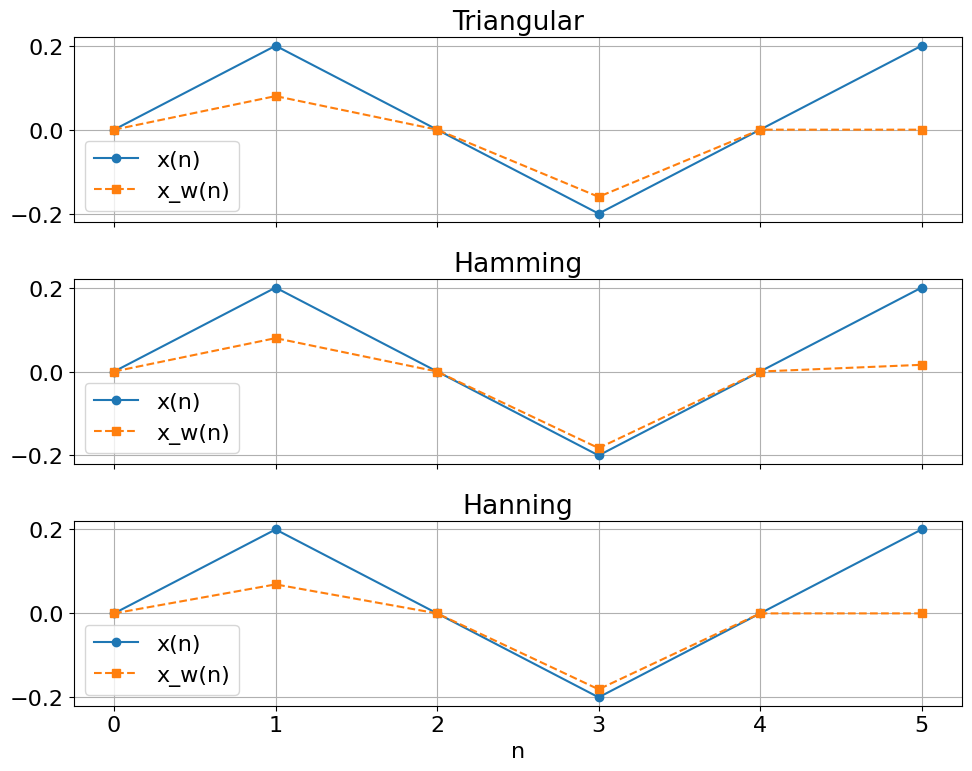

triangular window * x: [ 0.    0.08  0.   -0.16  0.    0.  ]
hamming window * x: [ 0.          0.07957044  0.         -0.18242956  0.          0.016     ]
hanning window * x: [ 0.         0.0690983  0.        -0.1809017  0.         0.       ]


In [14]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([0, 0.2, 0, -0.2, 0, 0.2])
N = len(x)

w_tri = np.bartlett(N)
w_ham = np.hamming(N)
w_han = np.hanning(N)


print(f"triangular window: {w_tri}")
print(f"hamming window: {w_ham}")
print(f"hanning window: {w_han}")

# Plot the windows
n = np.arange(N)
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)
for axis, w, name in zip(
    ax,
    (w_tri, w_ham, w_han),
    ("Triangular", "Hamming", "Hanning"),
):
    axis.plot(n, x, "o-", label="x(n)")
    axis.plot(n, x * w, "s--", label="x_w(n)")
    axis.set_title(name)
    axis.legend()
    axis.grid(True)
ax[-1].set_xlabel("n")
plt.tight_layout()
plt.show()

print(f"triangular window * x: {x * w_tri}")
print(f"hamming window * x: {x * w_ham}")
print(f"hanning window * x: {x * w_han}")


Triangluar window giver: $x_{triangular}(n)=[0, 0.08, 0, -0.16, 0, 0]$

Hamming window giver: $x_{hamming}(n)=[0, 0.07957044, 0, -0.18242956, 0, 0.016]$

Hanning window giver: $x_{hanning}(n)=[0, 0.0690983, 0, -0.1809017, 0, 0]$

#### 4.20
Given a sinusoid
$$
x(n) = 2*sin(2000 * 2 \pi * \frac{n}{8000})
$$
obtained by using the sampling rate of $f_s=8000Hz$, we apply the DFT to compute the ampltude spectrum.

a) Determine the frequency resolution when the data length is 100 samples. Without using the window function, is there any spectral leakage in the computed spectrum? Explain.

Frekvensopløsningen bliver $\Delta f = f_s /N = 8000/100 = 80Hz$

Da 2000Hz rammer en bin (altså da $N * 2000/8000 = 25$ er et heltal) er der ingen spektral lækage.


b) Determine the frequency resolution when the data length is 73 samples. Without using the window functions, is there any spectral leakage in the computed spectum? Explain.

Når $N=73$ kommer der til at være spektral lækage idet frekvensopløsningen er $\Delta f = \frac{8000}{73}\approx 109.59Hz$ og $\frac{2000}{109.59}=18.25$
Altså rammer frekvensen på 2000Hz ikke i en bin præcist hvilket vil sige at der opstår spektral lækage.

Dette er illustreret nedenfor


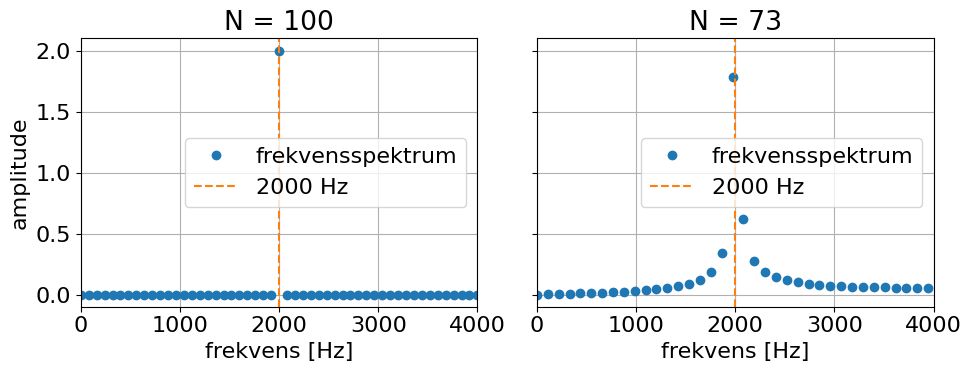

In [15]:
import numpy as np
import matplotlib.pyplot as plt

fs = 8000
f0 = 2000

def amplitude_spectrum(N):
    n = np.arange(N)
    x = 2 * np.sin(2 * np.pi * f0 * n / fs)
    X = np.fft.rfft(x)
    freq = np.fft.rfftfreq(N, d=1 / fs)
    amp = np.abs(X) * 2 / N
    return freq, amp


fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, N in zip(ax, (100, 73)):
    a.plot(*amplitude_spectrum(N), "o", label="frekvensspektrum")
    a.axvline(f0, color="C1", ls="--", label="2000 Hz")
    a.set_xlim(0, fs / 2)
    a.set_title(f"N = {N}")
    a.set_xlabel("frekvens [Hz]")
    a.legend()
ax[0].set_ylabel("amplitude")
fig.tight_layout()
plt.show()


Det kan ses på ovenstående frekvensspektrum at der opstår spektral lækage når N=73.

### 9. Diskussion og konklusion

I det undersøgte udsnit har myopati-signalet større samlet energi
og en lidt større andel af energi over 200 Hz end det raske
EMG-signal. Det stemmer med de hyppigere og skarpere udsving i
tidsplottet. Resultaterne gælder dog kun de valgte 630 samples.

EKG-analysen giver en gennemsnitlig puls på 62,66 slag/min,
svarende til cirka $1{,}044\,\mathrm{Hz}$ i frekvensspektret.
Variationen i RR-intervallerne viser HRV. STFT'en viser desuden,
hvornår QRS-kompleksernes frekvensindhold optræder, og at
komplekserne overordnet ligner hinanden.

Blodtrykssignalerne har forskellige pulsfrekvenser og amplituder.
Udglatning gør spektrenes overordnede form tydeligere, men skjuler
små detaljer. Zero-padding giver en tættere frekvensakse uden ny
information, mens vinduesfunktioner reducerer spektrallækage på
bekostning af bredere toppe.

Samlet supplerer tids- og frekvensanalyserne hinanden.
Fortolkningen afhænger af signallængde og analyseparametre,
og de korte udsnit begrænser, hvor generelle konklusioner vi
kan drage.